# Volume meshes of real skins

`41_octree_mesh.ipynb` introduces `octree_mesh` on a sphere. A sphere is the easy case: smooth, convex, no sharp edges. This notebook meshes harder skins:

- the **Stanford bunny** (`example/Bunny.stl`, 112 402 triangles of a scan: thin ears, concave folds, scan noise that reads as hundreds of short creases);
- a **capped cylinder**, whose rims are sharp feature chains that must be recovered on fine graded skins;
- a **uniformly fine** mesh of the bunny, where the inside test used to dominate the time.

Every output is checked with `check_conformity`.

In [1]:
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
except Exception:  # pragma: no cover - PyVista is optional
    pv = None

# The Stanford bunny shipped with the examples ("Stanford Bunny -- Digitized!" by
# MakerBot, CC BY 3.0, see example/README.md): 112 402 triangles, closed.
BUNNY = os.path.join(os.path.dirname(os.getcwd()), 'Bunny.stl')


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


GL = gl_available()
print('PyVista rendering' if GL else 'matplotlib fallback (no off-screen GL)')


def to_pyvista(mesh):
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def show(img, title):
    plt.figure(figsize=(9, 7)); plt.imshow(img); plt.axis('off'); plt.title(title); plt.show()


def boundary_faces(mesh, keep=None):
    """The faces used once by the kept cells (all cells by default), as point arrays."""
    pts = np.asarray(mesh.points, dtype=float)
    if pts.shape[1] == 2:
        pts = np.column_stack([pts, np.zeros(len(pts))])
    seen = {}
    start = 0
    for cb in mesh.cells:
        conn = np.asarray(cb.data)
        faces = {'tetra': [(0, 1, 3), (1, 2, 3), (2, 0, 3), (0, 2, 1)],
                 'hexahedron': [(0, 3, 2, 1), (4, 5, 6, 7), (0, 1, 5, 4), (1, 2, 6, 5),
                                (2, 3, 7, 6), (3, 0, 4, 7)],
                 'triangle': [(0, 1, 2)], 'quad': [(0, 1, 2, 3)]}.get(cb.type, [])
        for c in range(len(conn)):
            if keep is not None and not keep[start + c]:
                continue
            for f in faces:
                ids = conn[c, list(f)]
                key = tuple(sorted(ids))
                seen[key] = None if key in seen else ids
        start += len(conn)
    return [pts[f] for f in seen.values() if f is not None]


def render_clip(mesh, title, scalars=None, cmap='viridis', normal='y', origin=None,
                points=None, edges=True, camera=(20, 25)):
    """A volume mesh cut open by a plane (y by default), optionally coloured by a
    cell array and with marked points: PyVista when GL is available, else the
    boundary faces of the kept half in a matplotlib 3-D collection."""
    p = np.asarray(mesh.points, dtype=float)
    origin = p.mean(axis=0) if origin is None else origin
    ax_n = 'xyz'.index(normal)
    if GL:
        grid = to_pyvista(mesh)
        half = grid.clip(normal=normal, origin=origin, crinkle=True)
        if points is not None and len(points):
            # Only the marks in the kept half (whole cells, so up to its far
            # face): the others would float in front of the cut.
            points = np.asarray(points, dtype=float)
            points = points[points[:, ax_n] <= half.bounds[2 * ax_n + 1]]
        pl = pv.Plotter(off_screen=True, window_size=(900, 700))
        pl.add_mesh(half, scalars=scalars, cmap=cmap, show_edges=edges,
                    edge_color='#333333', line_width=0.3, color='#c9d6df')
        if points is not None and len(points):
            pl.add_points(np.asarray(points, dtype=float), color='crimson', point_size=5,
                          render_points_as_spheres=True)
        pl.view_xz(negative=True)
        pl.camera.elevation, pl.camera.azimuth = camera
        img = pl.screenshot(return_img=True)
        pl.close()
        show(img, title)
        return
    if points is not None and len(points):
        points = np.asarray(points, dtype=float)
        points = points[points[:, ax_n] <= origin[ax_n]]
    keep = []
    for cb in mesh.cells:
        c = p[np.asarray(cb.data)].mean(axis=1)[:, ax_n]
        keep.extend(c < origin[ax_n])
    polys = boundary_faces(mesh, keep)
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(projection='3d')
    ax.add_collection3d(Poly3DCollection(polys, facecolors='#c9d6df', edgecolors='k',
                                         linewidths=0.1))
    if points is not None and len(points):
        q = np.asarray(points)
        ax.scatter(q[:, 0], q[:, 1], q[:, 2], c='crimson', s=2)
    ax.set_xlim(p[:, 0].min(), p[:, 0].max()); ax.set_ylim(p[:, 1].min(), p[:, 1].max())
    ax.set_zlim(p[:, 2].min(), p[:, 2].max()); ax.set_box_aspect(np.ptp(p, axis=0))
    ax.view_init(elev=18, azim=62); ax.set_axis_off(); ax.set_title(title)
    plt.show()


def show_report(report, keys):
    for k in keys:
        v = report[k]
        print(f'{k:32s} {v:.4g}' if isinstance(v, float) else f'{k:32s} {v}')
    for w in report.get('warnings', []):
        print('warning:', w)


PyVista rendering


## Graded tetrahedra inside the bunny

The default output: a graded body-centred cubic lattice cut to the skin by isosurface stuffing, with sharp corners and creases snapped, then optimised. On a scan, `feature_angle` decides what counts as a crease. At the default 30° the bunny's noise gives hundreds of short chains, so a larger angle keeps only the real creases.

In [2]:
bunny = mp.read(BUNNY)
t0 = time.perf_counter()
tets, rep = mp.octree_mesh(bunny, min_size=2.0, max_size=8.0, feature_angle=60,
                           return_report=True)
print(f'{time.perf_counter() - t0:.1f} s')
show_report(rep, ['num_tetrahedra', 'num_points', 'min_dihedral', 'max_dihedral',
                  'min_scaled_jacobian', 'num_inverted', 'hausdorff_to_skin',
                  'num_corners', 'num_corners_snapped', 'num_feature_chains',
                  'num_feature_chains_missed', 'num_boundary_edges_open'])
print('conforming:', mp.check_conformity(tets, return_report=True)[1]['conforming'])

meshio warning [octree_mesh.cpp:371] meshio++: octree_mesh: 3 of 34 feature corners not recovered
meshio warning [octree_mesh.cpp:371] meshio++: octree_mesh: 9 of 28 feature chains not recovered


meshio warning [octree_mesh.cpp:371] meshio++: octree_mesh: the smallest dihedral angle is 2.711423 degrees


16.1 s
num_tetrahedra                   278844
num_points                       56473
min_dihedral                     2.711
max_dihedral                     175.9
min_scaled_jacobian              0.01433
num_inverted                     0
hausdorff_to_skin                0.5087
num_corners                      34
num_corners_snapped              31
num_feature_chains               28
num_feature_chains_missed        9
num_boundary_edges_open          0


conforming: True


2026-10-27 17:42:54.576 (  45.998s) [    7FA30A7D9080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


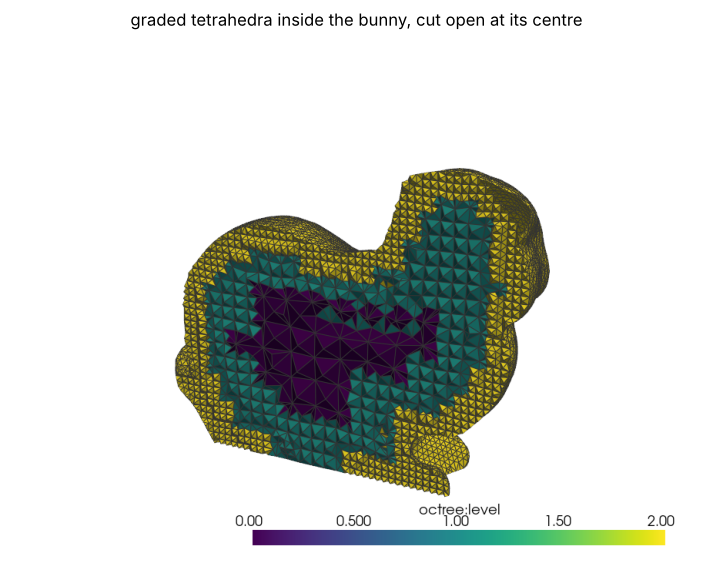

In [3]:
render_clip(tets, 'graded tetrahedra inside the bunny, cut open at its centre', scalars='octree:level')

## Sharp rims on fine skins

A cylinder's rims are feature chains. Each rim vertex is moved onto the rim under a guard: no tetrahedron may lose its volume or fall below a two-degree dihedral angle. On fine graded skins the tetrahedra beside a rim are thin, and the guard used to count the slivers *outside* the skin, which the output drops anyway, so rim vertices were held off their chains. The guard now counts only the tetrahedra that reach the output, and every chain is recovered.

In [4]:
cylinder = mp.convert_cells(mp.extract_surface(mp.cylinder(radius=0.5, height=2.0, nxy=48, nz=16)),
                            mode='simplexify')
for min_size in (0.2, 0.1, 0.05):
    m, r = mp.octree_mesh(cylinder, min_size=min_size, max_size=0.5, return_report=True)
    print(f"min_size {min_size:5.3f}: {r['num_tetrahedra']:6d} tets, chains missed "
          f"{r['num_feature_chains_missed']} of {r['num_feature_chains']}, corners "
          f"{r['num_corners_snapped']} of {r['num_corners']}, min dihedral {r['min_dihedral']:.1f}°, "
          f"Hausdorff {r['hausdorff_to_skin']:.4f}")
rims = m

min_size 0.200:   2632 tets, chains missed 0 of 4, corners 4 of 4, min dihedral 34.1°, Hausdorff 0.0136


min_size 0.100:  20180 tets, chains missed 0 of 4, corners 4 of 4, min dihedral 18.4°, Hausdorff 0.0029


min_size 0.050:  47260 tets, chains missed 0 of 4, corners 4 of 4, min dihedral 16.1°, Hausdorff 0.0029


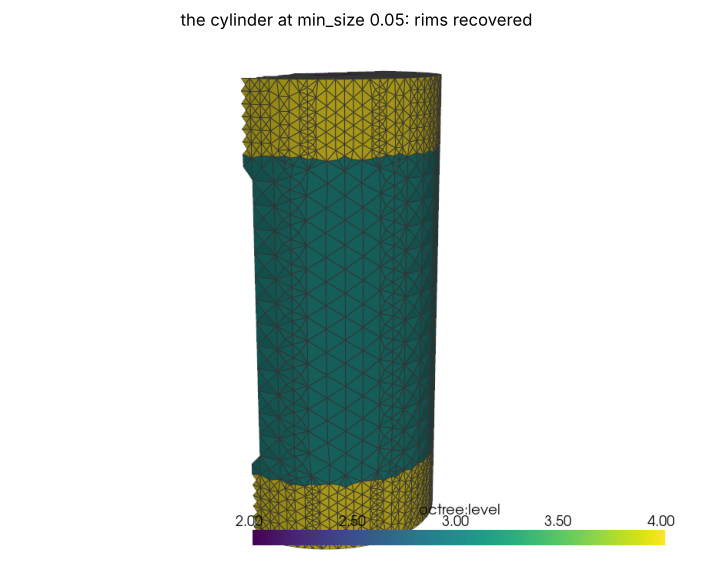

In [5]:
render_clip(rims, 'the cylinder at min_size 0.05: rims recovered', scalars='octree:level',
            normal='x', camera=(15, 35))

## Uniformly fine: the inside test, flooded

Inside and outside come from the generalised winding number, evaluated at every lattice point. On a uniformly fine mesh most points lie far from the skin. For a closed skin the winding number there is an integer that only changes across the skin, so the leaves the skin does not reach are joined into regions, each region takes one value, and only the points beside the skin are evaluated. The output is byte-identical; `num_winding_skipped` counts the points that were not evaluated.

9.5 s, 92612 points, 708045 winding numbers flooded, 0 rechecked
stage timings (s): {'skin': 0.12, 'size_field': 0.21, 'octree': 1.65, 'output': 7.45, 'quality': 0.03}


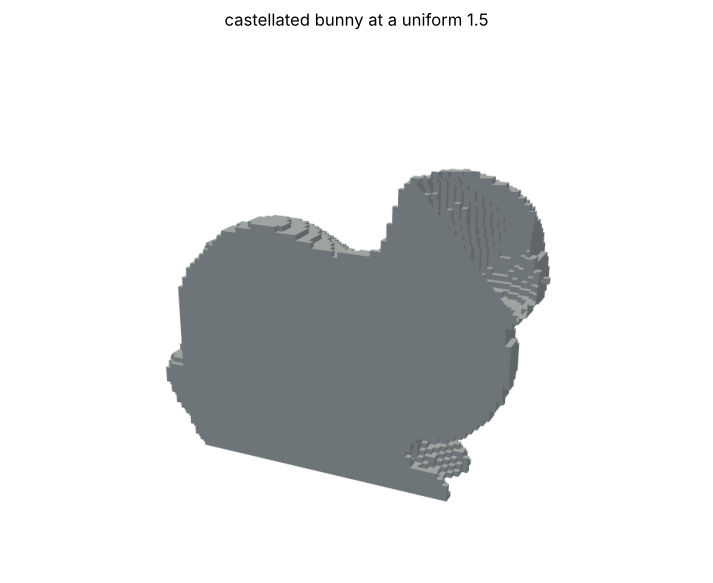

In [6]:
t0 = time.perf_counter()
cells, rep = mp.octree_mesh(bunny, output='castellated', min_size=1.5, max_size=1.5,
                            return_report=True)
print(f'{time.perf_counter() - t0:.1f} s, {rep["num_points"]} points, '
      f'{rep["num_winding_skipped"]} winding numbers flooded, {rep["num_winding_rechecks"]} rechecked')
print('stage timings (s):', {k: round(v, 2) for k, v in rep['timings'].items()})
render_clip(cells, 'castellated bunny at a uniform 1.5', edges=False)

## Hexahedra

`output="hex"` makes hexahedra only: a uniform grid at the skin size is made manifold, pillowed, fitted to the skin and untangled. On a scan the fit is not always clean: here a few hexahedra stay inverted after untangling, and the report (`num_inverted`, `min_scaled_jacobian`) and the warnings say so rather than hiding them. Run `check_quality` on such a mesh before a solver sees it.

meshio warning [octree_mesh.cpp:371] meshio++: octree_mesh: 2 of 28 feature chains not recovered


meshio warning [octree_mesh.cpp:371] meshio++: octree_mesh: untangling left a hexahedron with a non-positive corner Jacobian; raise untangle_iterations or lower surface_size


meshio warning [octree_mesh.cpp:371] meshio++: octree_mesh: 5 cells have a non-positive volume


num_hexahedra                    19306
min_scaled_jacobian              -0.949
num_inverted                     5
hausdorff_to_skin                1.499


conforming: True


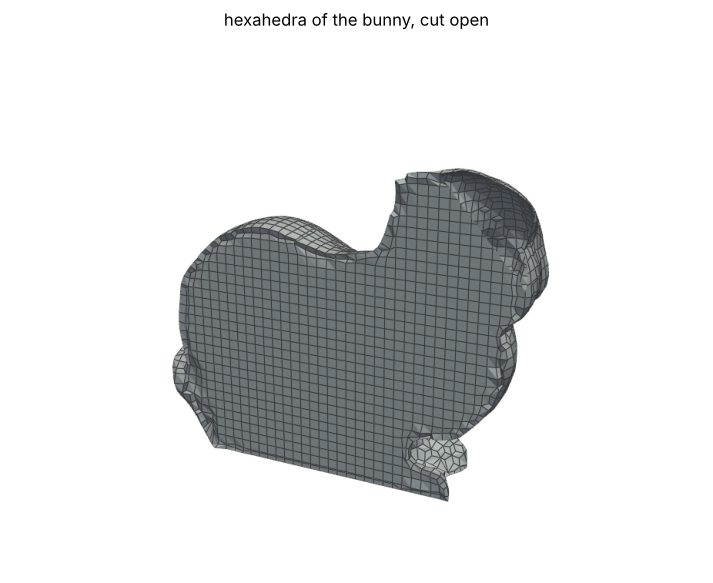

In [7]:
hexes, rep = mp.octree_mesh(bunny, output='hex', surface_size=3.0, feature_angle=60,
                            return_report=True)
show_report(rep, ['num_hexahedra', 'min_scaled_jacobian', 'num_inverted', 'hausdorff_to_skin'])
print('conforming:', mp.check_conformity(hexes, return_report=True)[1]['conforming'])
render_clip(hexes, 'hexahedra of the bunny, cut open')